In [2]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 1.0 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/8.4 MB 1.1 MB/s eta 0:00:07
   ----- ---------------------------------- 1.0/8.4 MB 1.2 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.4 MB 1.2 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.4 MB 1.3 MB/s eta 0:00:06
   ----------- ---------------------------- 2.4/8.4 MB 1.6 MB/s eta 0:00:04
   ----------- ---------------------------- 2.4/8.4 MB 1.6 MB/s eta 0:00:04
   ------------- -------------------------- 2.9/8.4 MB 1.5 MB/s eta 0:00:04
   --------------- ------------------------ 3.1/8.4 MB 1.5 MB/s eta 0:00:04
   -------------------- ------------------- 4.2/8.4 MB 1.9 MB/s eta 0:00:03
   ------------------------- ----


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# Load the original dataset
df = pd.read_csv("../Datasets/dataset.csv")

# Remove the identifier column
df = df.drop("loan_id", axis=1)

# Convert target variable
df["loan_status"] = df["loan_status"].map({"y": 1, "n": 0})

# Separate input features and target
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

# First split: 85% temporary data, 15% test data
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Second split: approximately 15% of total data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1765,
    random_state=42,
    stratify=y_temp
)

print("Dataset split successfully!")
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTarget distribution:")
print("Training:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTest:")
print(y_test.value_counts(normalize=True) * 100)

Dataset split successfully!
Training set: (429, 11)
Validation set: (92, 11)
Test set: (93, 11)

Target distribution:
Training:
loan_status
1    68.764569
0    31.235431
Name: proportion, dtype: float64

Validation:
loan_status
1    68.478261
0    31.521739
Name: proportion, dtype: float64

Test:
loan_status
1    68.817204
0    31.182796
Name: proportion, dtype: float64


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [8]:
# Identify numerical and categorical features

numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history']

Categorical features:
['gender', 'married', 'dependents', 'education', 'self_employed', 'property_area']


C:\Users\polis\AppData\Local\Temp\ipykernel_20924\3474641334.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()


In [9]:
# Preprocessing pipeline

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
# Fit preprocessing only on the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data using the fitted preprocessor
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)
print("Test data shape:", X_test_processed.shape)

Preprocessing completed successfully!
Training data shape: (429, 20)
Validation data shape: (92, 20)
Test data shape: (93, 20)


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [12]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [13]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    oob_score=True,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully!")
print("OOB Score:", random_forest_model.oob_score_)

Random Forest trained successfully!
OOB Score: 0.7575757575757576


In [15]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 7.2 MB/s eta 0:00:07
   - -------------------------------------- 2.4/48.9 MB 7.5 MB/s eta 0:00:07
   -- ------------------------------------- 3.4/48.9 MB 6.4 MB/s eta 0:00:08
   --- ------------------------------------ 3.9/48.9 MB 5.2 MB/s eta 0:00:09
   --- ------------------------------------ 4.7/48.9 MB 4.8 MB/s eta 0:00:10
   ---- ----------------------------------- 5.8/48.9 MB 4.9 MB/s eta 0:00:09
   ----- ---------------------------------- 7.3/48.9 MB 5.2 MB/s eta 0:00:09
   ------ --------------------------------- 7.9/48.9 MB 5.1 MB/s eta 0:00:09
   ------- -------------------------------- 8.7/48.9 MB 4.6 MB/s eta 0:00:09
   -------- ------------------------------- 10.0/48.9 MB 4.8 MB/s eta 0:00:09
   --------- ------------------------------ 11.8/48.9 MB 5.2 MB/s eta 0:00:08
   ---------- ----------------------------- 12.8/48.9 MB 5.2 MB/s eta 0:00:07
   


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
from xgboost import XGBClassifier

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
xgb_model.fit(X_train_processed, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Store all trained models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():
    # Predictions
    y_val_pred = model.predict(X_val_processed)

    # Probability for positive class
    y_val_prob = model.predict_proba(X_val_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1-Score": f1_score(y_val, y_val_pred),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob),
        "PR-AUC": average_precision_score(y_val, y_val_prob)
    })

results_df = pd.DataFrame(results)

print("Validation Set Model Comparison:")
display(results_df.round(4))

Validation Set Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7826,0.7722,0.9683,0.8592,0.7044,0.7975
1,Decision Tree,0.7174,0.8033,0.7778,0.7903,0.6820,0.7769
2,Random Forest,0.7717,0.7838,0.9206,0.8467,0.7997,0.8942
3,XGBoost,0.7826,0.8028,0.9048,0.8507,0.7581,0.8403


In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.pipeline import Pipeline

# Use the original training data, not the already processed arrays
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create complete pipelines
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

decision_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        oob_score=True,
        n_jobs=-1
    ))
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric="logloss"
    ))
])

cv_models = {
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline,
    "XGBoost": xgb_pipeline
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv_results = []

for name, pipeline in cv_models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Results:")
display(cv_results_df.round(4))

5-Fold Cross-Validation Results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8042,0.7878,0.9797,0.8732,0.7246,0.8121
1,Decision Tree,0.7015,0.7948,0.7661,0.7791,0.6623,0.7697
2,Random Forest,0.7623,0.7866,0.8983,0.8386,0.7604,0.8506
3,XGBoost,0.7692,0.7924,0.9017,0.8430,0.7544,0.8471


In [19]:
from sklearn.model_selection import RandomizedSearchCV

# -----------------------------
# 1. Logistic Regression tuning
# -----------------------------

logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

logistic_search = RandomizedSearchCV(
    logistic_pipeline,
    param_distributions=logistic_param_grid,
    n_iter=8,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)

print("Logistic Regression tuning completed!")
print("Best Parameters:", logistic_search.best_params_)
print("Best CV ROC-AUC:", logistic_search.best_score_)


# -----------------------------
# 2. Random Forest tuning
# -----------------------------

rf_param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 3, 5, 7, 10],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    random_forest_pipeline,
    param_distributions=rf_param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("\nRandom Forest tuning completed!")
print("Best Parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", rf_search.best_score_)


# -----------------------------
# 3. XGBoost tuning
# -----------------------------

xgb_param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("\nXGBoost tuning completed!")
print("Best Parameters:", xgb_search.best_params_)
print("Best CV ROC-AUC:", xgb_search.best_score_)

Logistic Regression tuning completed!
Best Parameters: {'model__solver': 'liblinear', 'model__C': 0.1}
Best CV ROC-AUC: 0.7327876768554734

Random Forest tuning completed!
Best Parameters: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'log2', 'model__max_depth': None}
Best CV ROC-AUC: 0.7672219807813028

XGBoost tuning completed!
Best Parameters: {'model__subsample': 0.9, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
Best CV ROC-AUC: 0.7746825051909798


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Store tuned models
tuned_models = {
    "Tuned Logistic Regression": logistic_search.best_estimator_,
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned XGBoost": xgb_search.best_estimator_
}

validation_results = []

for name, model in tuned_models.items():
    y_val_pred = model.predict(X_val)
    y_val_prob = model.predict_proba(X_val)[:, 1]

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1-Score": f1_score(y_val, y_val_pred),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob),
        "PR-AUC": average_precision_score(y_val, y_val_prob)
    })

tuned_validation_df = pd.DataFrame(validation_results)

print("Tuned Model Validation Results:")
display(tuned_validation_df.round(4))

Tuned Model Validation Results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Tuned Logistic Regression,0.7826,0.7722,0.9683,0.8592,0.7110,0.8081
1,Tuned Random Forest,0.7826,0.7722,0.9683,0.8592,0.7745,0.8660
2,Tuned XGBoost,0.7500,0.7703,0.9048,0.8321,0.7340,0.8359


In [21]:
from sklearn.base import clone

# Combine training and validation data
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

# Create a fresh copy of the tuned Random Forest pipeline
final_rf_model = clone(rf_search.best_estimator_)

# Train on training + validation data
final_rf_model.fit(X_train_final, y_train_final)

print("Final Random Forest trained successfully!")
print("Final training data:", X_train_final.shape)

Final Random Forest trained successfully!
Final training data: (521, 11)


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Predict on the untouched test set
y_test_pred = final_rf_model.predict(X_test)
y_test_prob = final_rf_model.predict_proba(X_test)[:, 1]

# Calculate final metrics
final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred)
final_recall = recall_score(y_test, y_test_pred)
final_f1 = f1_score(y_test, y_test_pred)
final_roc_auc = roc_auc_score(y_test, y_test_prob)
final_pr_auc = average_precision_score(y_test, y_test_prob)

print("Final Random Forest Test Results")
print("--------------------------------")
print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1-Score : {final_f1:.4f}")
print(f"ROC-AUC  : {final_roc_auc:.4f}")
print(f"PR-AUC   : {final_pr_auc:.4f}")

Final Random Forest Test Results
--------------------------------
Accuracy : 0.8387
Precision: 0.8267
Recall   : 0.9688
F1-Score : 0.8921
ROC-AUC  : 0.7699
PR-AUC   : 0.8428


Confusion Matrix:
[[16 13]
 [ 2 62]]


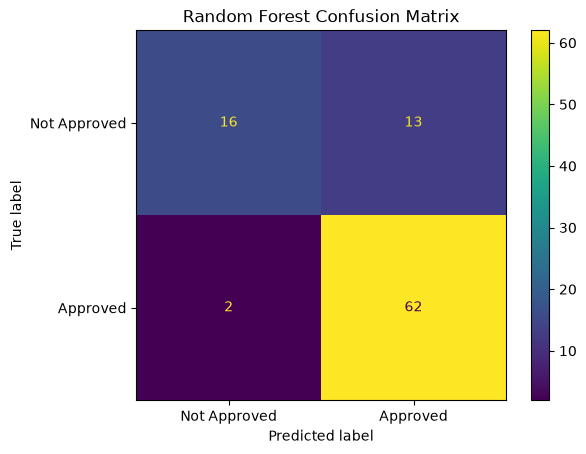

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Approved", "Approved"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

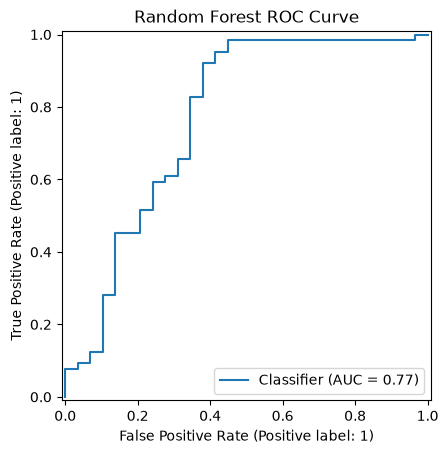

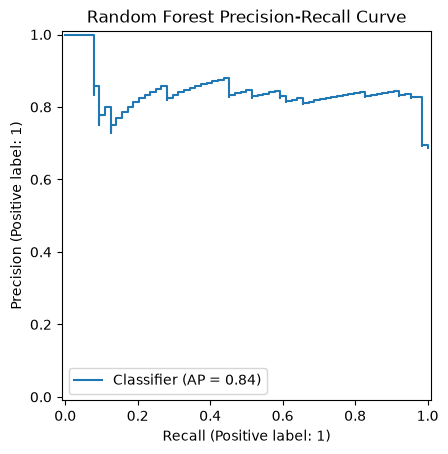

In [24]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

# ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob
)

plt.title("Random Forest ROC Curve")
plt.show()


# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob
)

plt.title("Random Forest Precision-Recall Curve")
plt.show()

In [25]:
%pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/43.0 MB 9.1 MB/s eta 0:00:05
   - -------------------------------------- 1.6/43.0 MB 4.3 MB/s eta 0:00:10
   -- ------------------------------------- 2.6/43.0 MB 4.5 MB/s eta 0:00:09
   -- ------------------------------------- 3.1/43.0 MB 4.1 MB/s eta 0:00:10
   --- ------------------------------------ 3.9/43.0 MB 3.9 MB/s eta 0:00:10
   --- ------------------------------------ 4.2/43.0 MB 3.5 MB/s eta 0:00:12
   ---- ----------------------------------- 5.2/43.0 MB 3.7 MB/s eta 0:00:11
   ----- ---------------------------------- 6.3/43.0 MB 3.9 MB/s eta 0:00:10
   ------ --------------------------------- 6.6/43.0 MB 3.8 MB/s eta 0:00:10
   ------ --------------------------------- 7.3/43.0 MB 3.6 MB/s eta 0:00:10
   ------- -------------------------------- 8.1/43.0 MB 3.6 MB/s eta 0:00:10
   -------- ------------------------------- 9.2/43.0 MB 3.7 MB/s eta 0:00:10
   ---


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
import shap
import matplotlib.pyplot as plt

# Get the fitted preprocessing pipeline and Random Forest model
fitted_preprocessor = final_rf_model.named_steps["preprocessor"]
fitted_rf = final_rf_model.named_steps["model"]

# Transform the test data using the already-fitted preprocessing pipeline
X_test_shap = fitted_preprocessor.transform(X_test)

# Convert to dense format for SHAP if necessary
if hasattr(X_test_shap, "toarray"):
    X_test_shap = X_test_shap.toarray()

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

print("SHAP data prepared successfully!")
print("Number of processed features:", len(feature_names))

c:\Users\polis\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP data prepared successfully!
Number of processed features: 20


In [27]:
# Create SHAP explainer for the final Random Forest
explainer = shap.TreeExplainer(fitted_rf)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


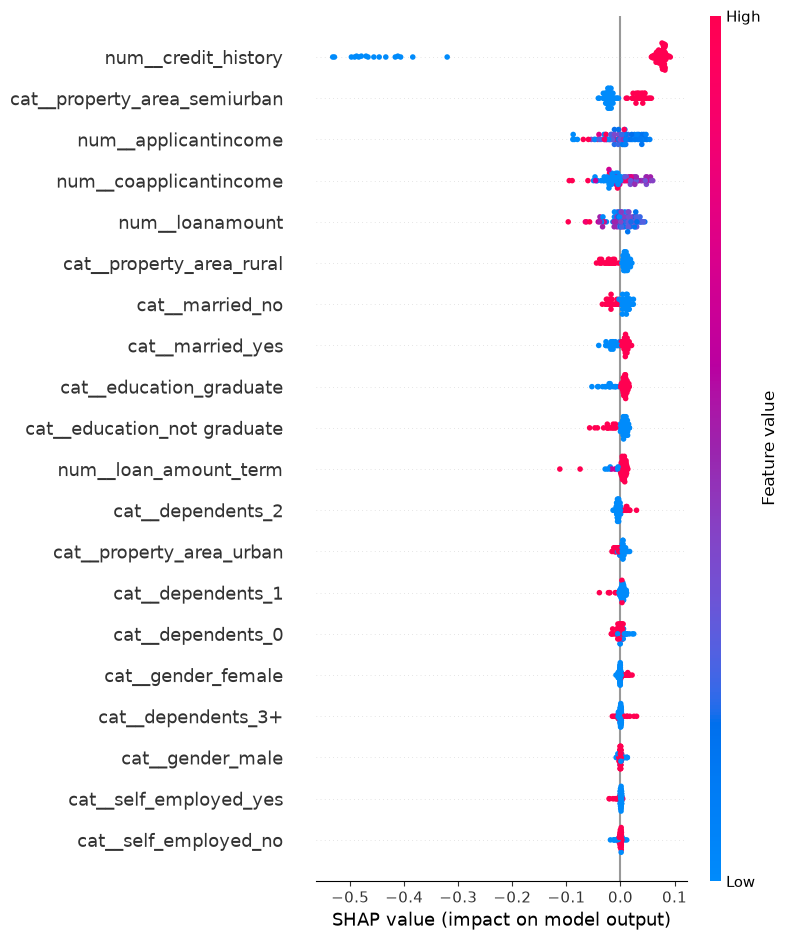

In [28]:
# SHAP feature importance

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values_for_plot = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_values_for_plot = shap_values[:, :, 1]
else:
    shap_values_for_plot = shap_values

# Create SHAP summary plot
shap.summary_plot(
    shap_values_for_plot,
    X_test_shap,
    feature_names=feature_names,
    show=True
)

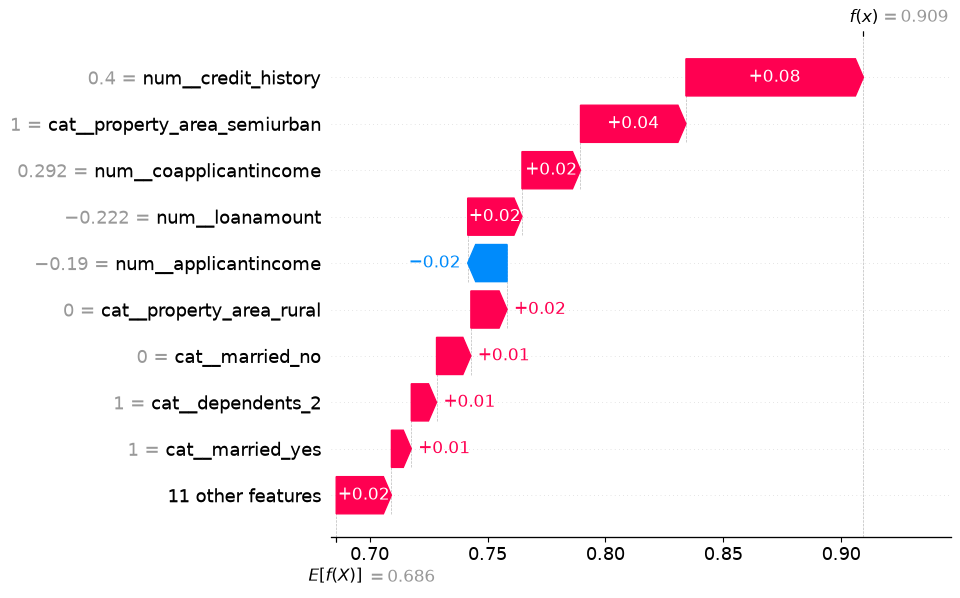

In [29]:
# Explain one individual loan application

sample_index = 0

sample_data = X_test_shap[sample_index]

# Select SHAP values for the Approved class
if isinstance(shap_values, list):
    sample_shap_values = shap_values[1][sample_index]
    base_value = explainer.expected_value[1]
elif len(shap_values.shape) == 3:
    sample_shap_values = shap_values[sample_index, :, 1]
    base_value = explainer.expected_value[1]
else:
    sample_shap_values = shap_values[sample_index]
    base_value = explainer.expected_value

# Create SHAP explanation
sample_explanation = shap.Explanation(
    values=sample_shap_values,
    base_values=base_value,
    data=sample_data,
    feature_names=feature_names
)

# Display waterfall plot
shap.plots.waterfall(sample_explanation, max_display=10)

In [30]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the test set
perm_result = permutation_importance(
    final_rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a DataFrame
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    "Importance_Mean",
    ascending=False
)

print("Permutation Feature Importance:")
display(permutation_df.round(4))

Permutation Feature Importance:


,Feature,Importance_Mean,Importance_Std
9,credit_history,0.2545,0.0507
10,property_area,0.0138,0.0183
8,loan_amount_term,-0.0030,0.0070
7,loanamount,-0.0033,0.0103
1,married,-0.0066,0.0128
0,gender,-0.0069,0.0064
6,coapplicantincome,-0.0077,0.0176
5,applicantincome,-0.0084,0.0253
4,self_employed,-0.0089,0.0055
2,dependents,-0.0107,0.0120


Brier Score: 0.1463


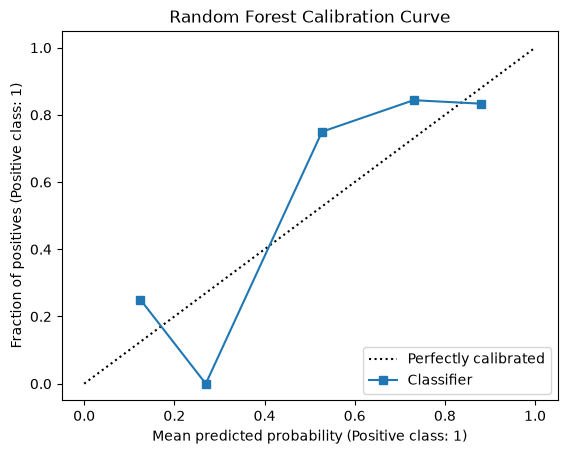

In [31]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Calculate Brier score
brier_score = brier_score_loss(y_test, y_test_prob)

print("Brier Score:", round(brier_score, 4))

# Create calibration reliability diagram
CalibrationDisplay.from_predictions(
    y_test,
    y_test_prob,
    n_bins=5,
    strategy="uniform"
)

plt.title("Random Forest Calibration Curve")
plt.show()

In [ ]:
import os
import joblib

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the complete trained pipeline
model_path = "../models/loan_approval_model.pkl"

joblib.dump(final_rf_model, model_path)

print("Final model saved successfully!")
print("Saved to:", model_path)

Final model saved successfully!
Saved to: ../models/loan_approval_model.pkl


In [2]:
# Get validation probabilities from the tuned Random Forest

threshold_model = rf_search.best_estimator_

# Use one CPU thread to avoid unnecessary parallel overhead
threshold_model.named_steps["model"].set_params(n_jobs=1)

y_val_prob = threshold_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated successfully!")
print(y_val_prob[:10])

NameError: name 'rf_search' is not defined

In [3]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Create a fresh preprocessing object
clean_preprocessor = clone(preprocessor)

# Create a fresh tuned Random Forest
clean_rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features="log2",
    max_depth=None,
    random_state=42,
    n_jobs=1
)

# Complete leakage-safe pipeline
clean_rf_pipeline = Pipeline([
    ("preprocessor", clean_preprocessor),
    ("model", clean_rf_model)
])

# Train ONLY on the original training set
clean_rf_pipeline.fit(X_train, y_train)

print("Clean tuned Random Forest trained successfully!")

# Get validation probabilities
y_val_prob = clean_rf_pipeline.predict_proba(X_val)[:, 1]

print("Validation probabilities generated successfully!")
print(y_val_prob[:10])

NameError: name 'preprocessor' is not defined

In [ ]:
print("Kernel is working!")

Kernel is working!


In [4]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier


# --------------------------------------------------
# 1. Load original dataset
# --------------------------------------------------

df = pd.read_csv("../Datasets/dataset.csv")

# Remove ID
df = df.drop("loan_id", axis=1)

# Convert target
df["loan_status"] = df["loan_status"].map({"y": 1, "n": 0})


# --------------------------------------------------
# 2. Separate features and target
# --------------------------------------------------

X = df.drop("loan_status", axis=1)
y = df["loan_status"]


# --------------------------------------------------
# 3. Recreate the SAME train/validation/test split
# --------------------------------------------------

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1765,
    random_state=42,
    stratify=y_temp
)


# --------------------------------------------------
# 4. Identify feature types
# --------------------------------------------------

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()


# --------------------------------------------------
# 5. Create preprocessing pipeline
# --------------------------------------------------

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# --------------------------------------------------
# 6. Create the tuned Random Forest
# --------------------------------------------------

threshold_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_split=10,
        min_samples_leaf=2,
        max_features="log2",
        max_depth=None,
        random_state=42,
        n_jobs=1
    ))
])


# --------------------------------------------------
# 7. Train ONLY on training data
# --------------------------------------------------

threshold_model.fit(X_train, y_train)

print("Tuned Random Forest rebuilt successfully!")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


# --------------------------------------------------
# 8. Get validation probabilities
# --------------------------------------------------

y_val_prob = threshold_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated successfully!")
print(y_val_prob[:10])

C:\Users\polis\AppData\Local\Temp\ipykernel_5112\1648679845.py:61: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


Tuned Random Forest rebuilt successfully!
Training: (429, 11)
Validation: (92, 11)
Test: (93, 11)
Validation probabilities generated successfully!
[0.89549942 0.2390008  0.94674451 0.59304026 0.64127889 0.73914178
 0.89864385 0.81523243 0.73115726 0.71028098]


In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:

    y_val_threshold_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_threshold_pred
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val,
            y_val_threshold_pred
        ),
        "Precision": precision_score(
            y_val,
            y_val_threshold_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_val_threshold_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val,
            y_val_threshold_pred,
            zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "False Approvals": fp,
        "False Rejections": fn
    })

threshold_df = pd.DataFrame(threshold_results)

print("Validation Threshold Analysis:")
display(threshold_df.round(4))

Validation Threshold Analysis:


,Threshold,Accuracy,Precision,Recall,F1-Score,Specificity,False Approvals,False Rejections
0,0.30,0.7717,0.7561,0.9841,0.8552,0.3103,20,1
1,0.35,0.7935,0.7750,0.9841,0.8671,0.3793,18,1
2,0.40,0.7826,0.7722,0.9683,0.8592,0.3793,18,2
3,0.45,0.7826,0.7722,0.9683,0.8592,0.3793,18,2
4,0.50,0.7826,0.7722,0.9683,0.8592,0.3793,18,2
5,0.55,0.7609,0.7662,0.9365,0.8429,0.3793,18,4
6,0.60,0.7609,0.7887,0.8889,0.8358,0.4828,15,7
7,0.65,0.7717,0.8182,0.8571,0.8372,0.5862,12,9
8,0.70,0.7391,0.8545,0.7460,0.7966,0.7241,8,16
